# Q1 — Global value -> fraud structure (anchors)

From `num_grid_eda.md` (Q1). Question: for each numeric column, how does fraud
rate vary with the anchor value (floor of the value), and is that variation a
trend?

What this notebook computes, per column:

- **Anchor**: floor of the value. All six continuous numeric columns.
- **CV-mean fraud rate per anchor**: the frozen unified alarm-profile 5-fold
  split; the rate is computed within each fold's rows of that anchor, and the
  per-fold ratios are averaged (equal fold weights, as specified). The pooled
  rate (row-weighted) is also kept for comparison.
- **Bootstrap CI per anchor**: conditional on anchor membership, resample the
  anchor's rows (fraud count ~ Binomial(n_anchor, rate)) B = 200 times;
  percentile 2.5/97.5. This quantifies per-anchor noise honestly for small
  fraud counts. (It is a within-anchor bootstrap: it does not propagate
  uncertainty about which rows belong to the anchor.)
- **Counts per anchor**: empirical P(anchor) — how common each value is — and
  P(anchor & fraud) via the fraud counts.

Two plots per column, sharing the x-axis of anchor values:

1. absolute transaction counts per anchor;
2. fraud rate per anchor (CV-mean) with bootstrap CIs, for anchors with at
   least 50 rows, against the global fraud rate line.

Interpretation is deliberately deferred: after reviewing, we refine the
"what the data looks like" sections of `num_grid_eda.md`.

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ccf_ml.cross_validation.constants import ID_COLUMN, TARGET_COLUMN
from ccf_ml.file_utils import get_script_plot_dir, get_train_csv_path
from ccf_ml.region_modeling import load_alarm_profile_stratified_cv

COLUMNS = [
    "amount_usd",
    "account_balance_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "velocity_score",
    "merchant_risk_score",
]
MIN_ROWS_SHOWN = 50
B = 200
rng = np.random.default_rng(42)

train = pd.read_csv(get_train_csv_path())
y = train[TARGET_COLUMN].to_numpy(dtype=bool)

# frozen unified folds: fold id per row id
cv = load_alarm_profile_stratified_cv()
ids = train[ID_COLUMN].to_numpy(dtype=np.int64)
fold_of = np.full(len(train), -1, dtype=np.int64)
pos_by_id = np.full(int(ids.max()) + 1, -1, dtype=np.int64)
pos_by_id[ids] = np.arange(len(ids))
for fold in cv.folds:
    for record_id in fold.val_ids:
        fold_of[pos_by_id[int(record_id)]] = fold.fold_id
assert (fold_of >= 0).all()

anchors = {c: np.floor(train[c].to_numpy(dtype=np.float64)).astype(np.int64) for c in COLUMNS}
plot_dir = get_script_plot_dir("q1_global_structure", section="anchors", group="numerical_grid_structure")
print("rows:", len(train), "| folds:", cv.n_splits, "| plots ->", plot_dir)

Creating missing directory: C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\q1_global_structure\plots\anchors


rows: 699960 | folds: 5 | plots -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\q1_global_structure\plots\anchors


In [2]:
# CV-mean fraud rate per anchor = mean of the per-fold ratios (equal fold weights)
summary = {}
for column in COLUMNS:
    anchor = anchors[column]
    frame = pd.DataFrame({"anchor": anchor, "y": y, "fold": fold_of})
    fold_rates = []
    for fold_id in range(cv.n_splits):
        sub = frame[frame["fold"] == fold_id]
        agg = sub.groupby("anchor")["y"].agg(fraud="sum", rows="size")
        fold_rates.append((agg["fraud"] / agg["rows"]).rename(fold_id))
    per_fold = pd.concat(fold_rates, axis=1)
    total = frame.groupby("anchor")["y"].agg(fraud_total="sum", rows_total="size")
    table = total.join(per_fold)
    table["cv_mean_rate"] = per_fold.mean(axis=1)
    table["n_folds_present"] = per_fold.notna().sum(axis=1)
    table["pooled_rate"] = table["fraud_total"] / table["rows_total"]
    summary[column] = table.sort_index()
    frac = (table["n_folds_present"] == 5).mean()
    print(f"{column:24s} anchors={len(table):5d}  present in all 5 folds: {frac:.2%}")

amount_usd               anchors= 1144  present in all 5 folds: 59.35%
account_balance_usd      anchors= 4928  present in all 5 folds: 66.92%


hours_since_last_txn     anchors=   51  present in all 5 folds: 100.00%
distance_from_home_km    anchors=   56  present in all 5 folds: 96.43%


velocity_score           anchors=   73  present in all 5 folds: 90.41%
merchant_risk_score      anchors=   98  present in all 5 folds: 98.98%


In [3]:
# within-anchor bootstrap CIs (fraud count ~ Binomial(n, rate)), B resamples
for column, table in summary.items():
    n = table["rows_total"].to_numpy(dtype=np.int64)
    f = table["fraud_total"].to_numpy(dtype=np.int64)
    p = f / n
    draws = rng.binomial(n[:, None], p[:, None], size=(len(table), B)) / n[:, None]
    lo, hi = np.percentile(draws, [2.5, 97.5], axis=1)
    table["ci_lo"] = lo
    table["ci_hi"] = hi
print("bootstrap done, B =", B)

bootstrap done, B = 200


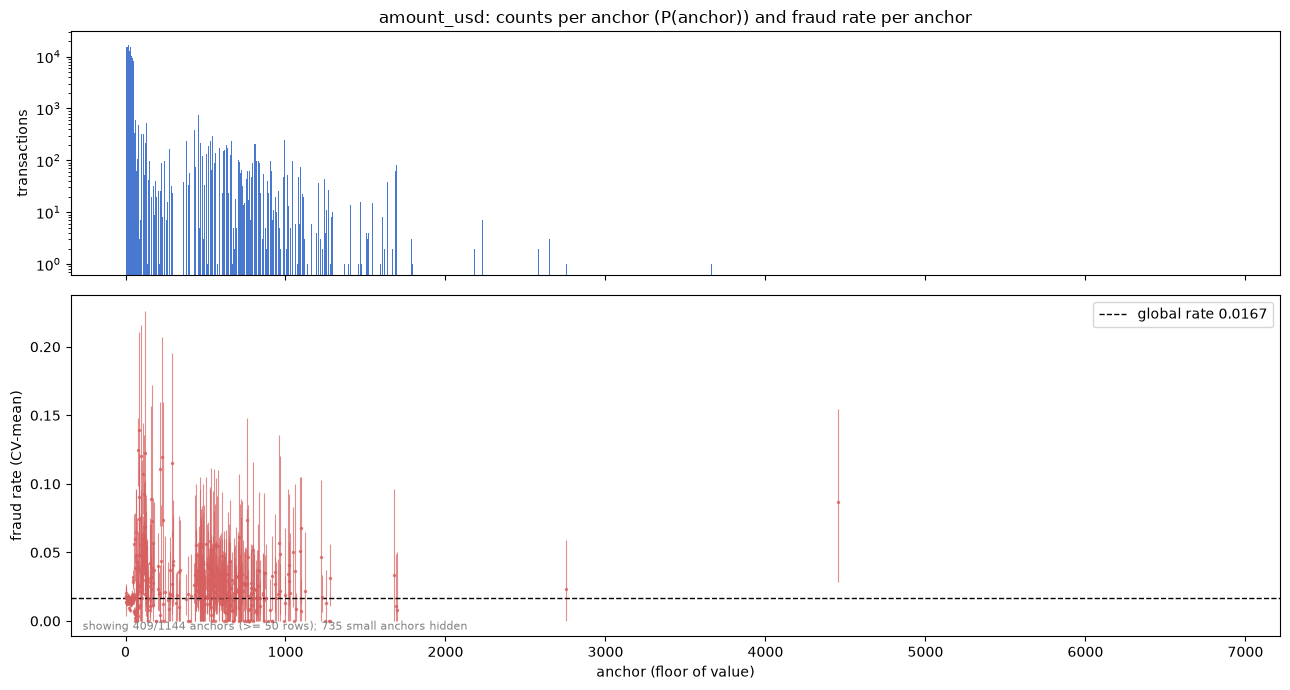

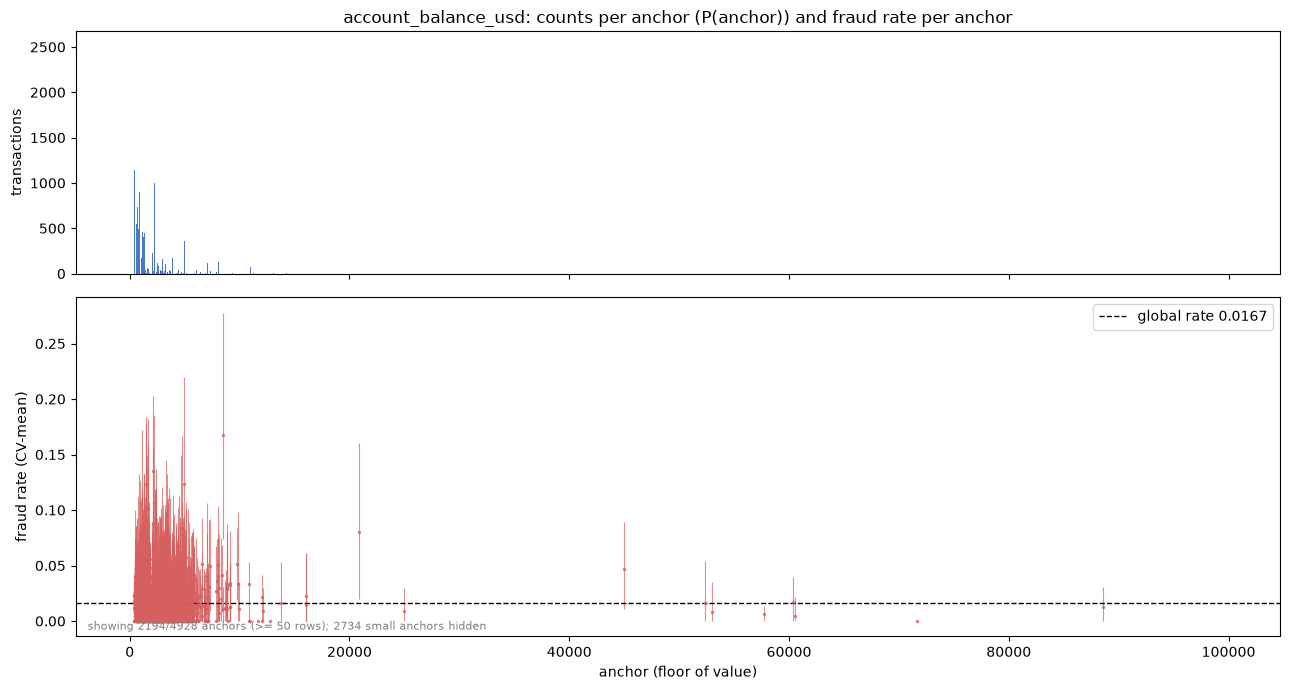

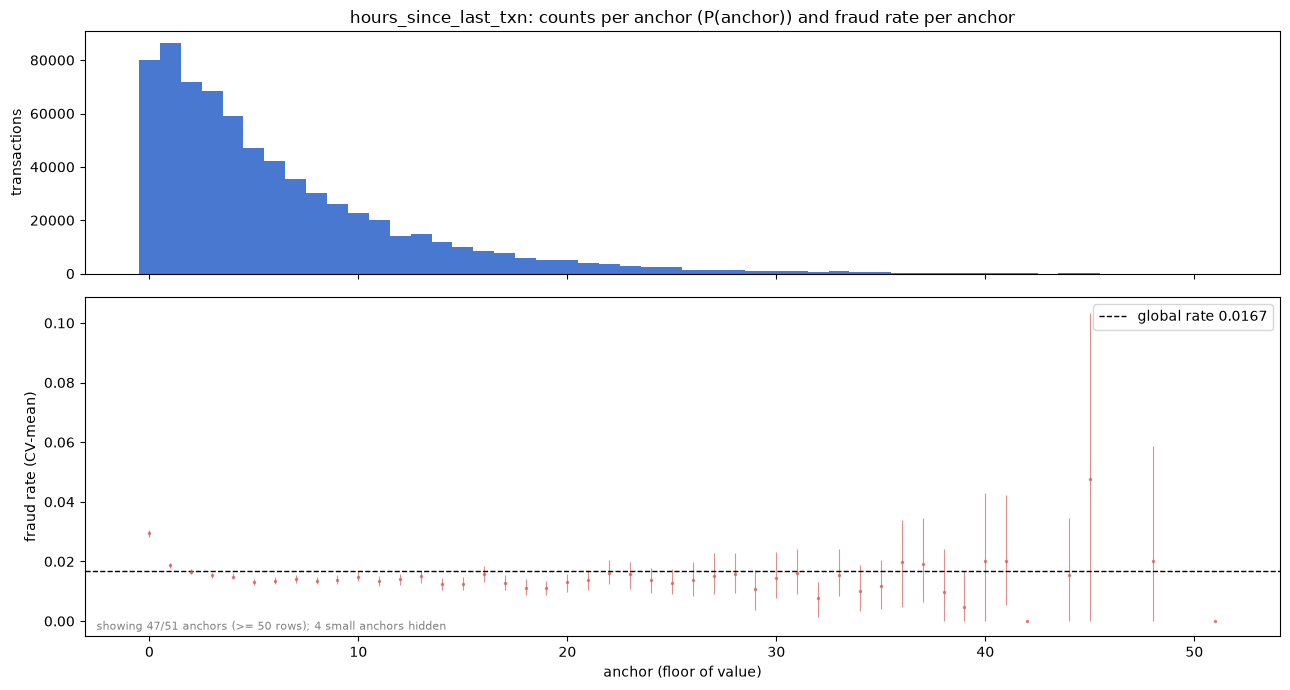

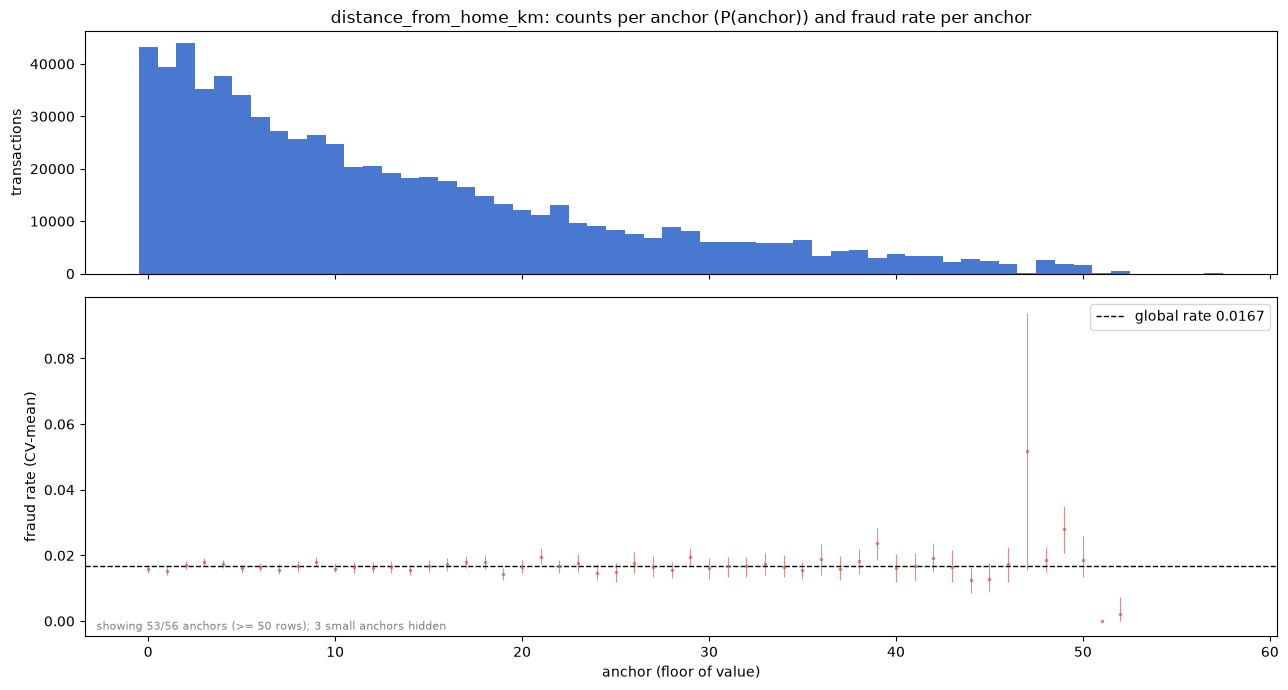

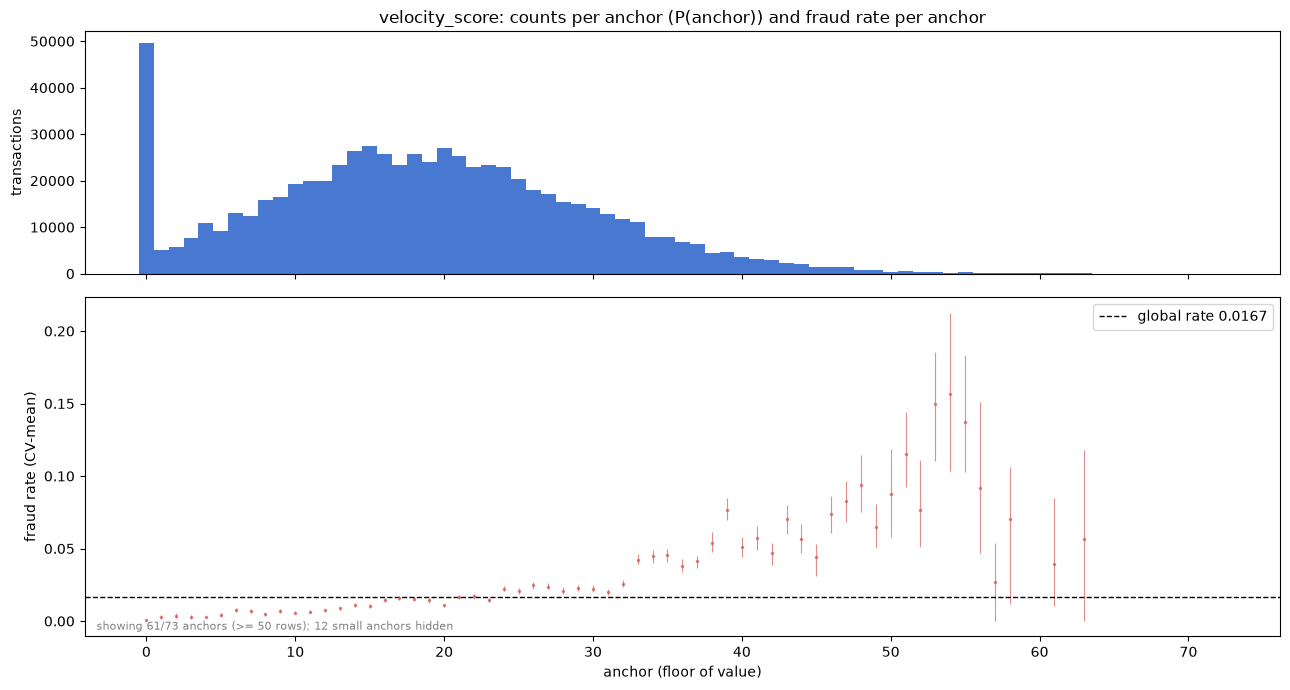

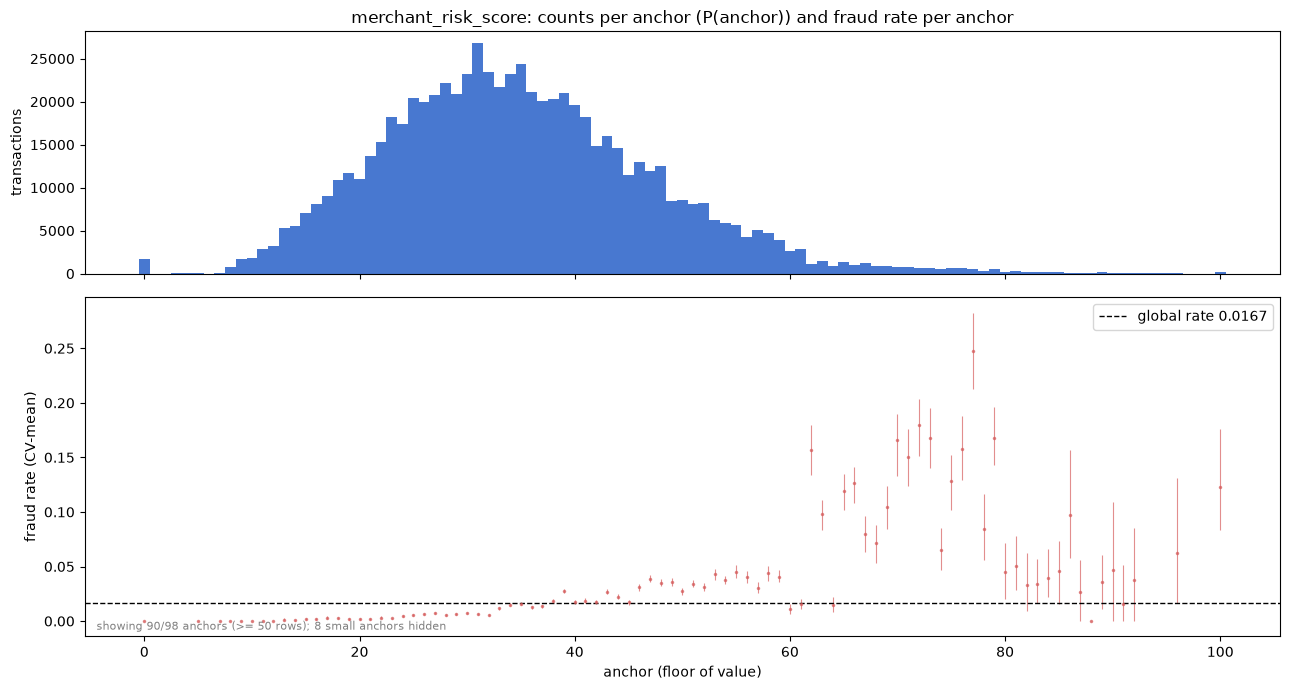

In [4]:
# Plot pair per column: (1) transaction counts per anchor, (2) fraud rate per anchor
global_rate = float(y.mean())
for column in COLUMNS:
    table = summary[column]
    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(13, 7), sharex=True,
        gridspec_kw={"height_ratios": [1, 1.4]},
    )
    ax_top.bar(table.index, table["rows_total"], width=1.0, color="#4878d0")
    ax_top.set_ylabel("transactions")
    if table["rows_total"].quantile(0.99) / max(table["rows_total"].median(), 1) > 50:
        ax_top.set_yscale("log")
    ax_top.set_title(f"{column}: counts per anchor (P(anchor)) and fraud rate per anchor")

    shown = table[table["rows_total"] >= MIN_ROWS_SHOWN]
    hidden = len(table) - len(shown)
    rate = shown["cv_mean_rate"].to_numpy()
    lo = shown["ci_lo"].to_numpy()
    hi = shown["ci_hi"].to_numpy()
    ax_bot.errorbar(
        shown.index, rate,
        yerr=np.vstack([np.clip(rate - lo, 0, None), np.clip(hi - rate, 0, None)]),
        fmt=".", ms=3, lw=0.8, color="#d65f5f", ecolor="#d65f5f", alpha=0.7,
    )
    ax_bot.axhline(global_rate, color="black", lw=1, ls="--",
                   label=f"global rate {global_rate:.4f}")
    ax_bot.set_ylabel("fraud rate (CV-mean)")
    ax_bot.set_xlabel("anchor (floor of value)")
    ax_bot.legend(loc="upper right")
    note = f"showing {len(shown)}/{len(table)} anchors (>= {MIN_ROWS_SHOWN} rows)"
    if hidden:
        note += f"; {hidden} small anchors hidden"
    ax_bot.text(0.01, 0.02, note, transform=ax_bot.transAxes, fontsize=8, color="gray")
    fig.tight_layout()
    fig.savefig(plot_dir / f"{column}_counts_rate.png", dpi=110)
    plt.show()

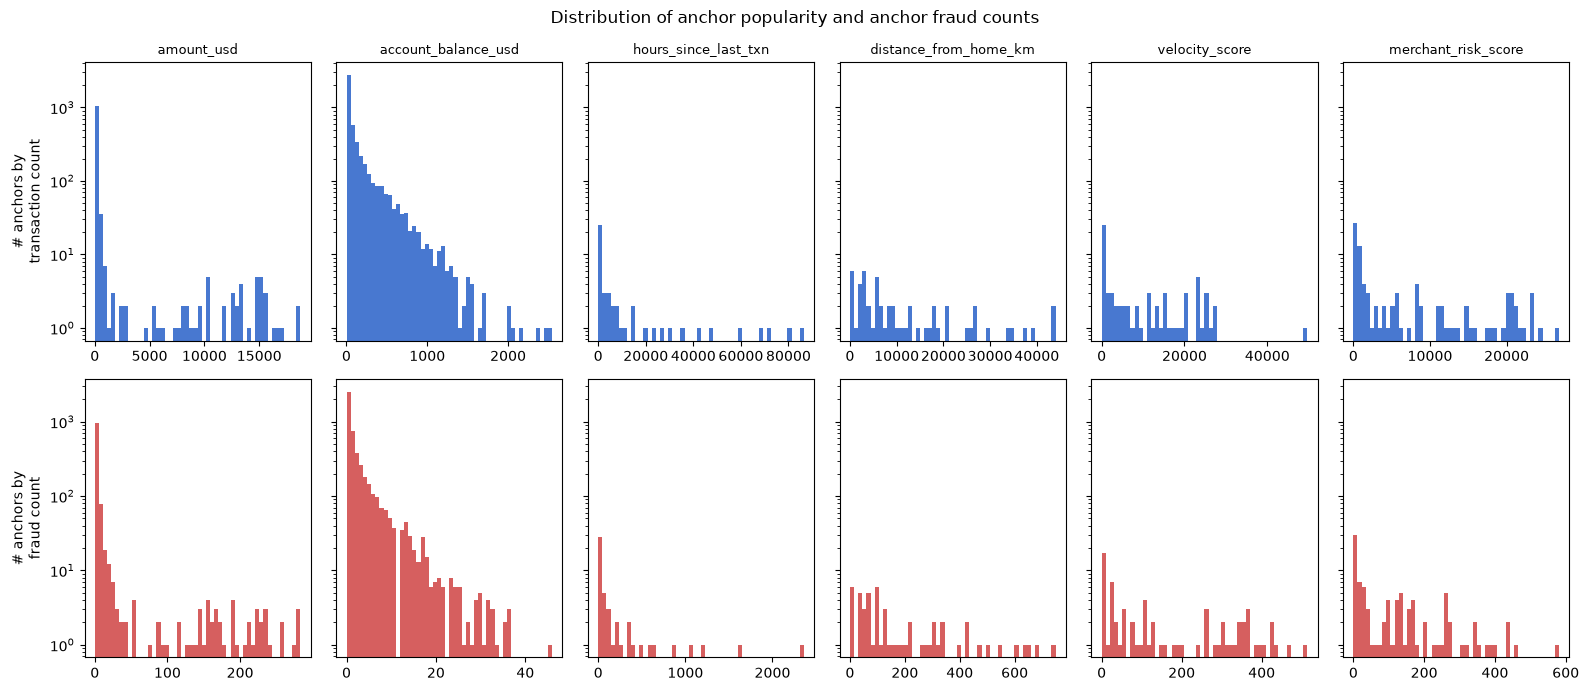

In [5]:
# P(anchor) and P(anchor & fraud) as distributions: how common is a commonness?
fig, axes = plt.subplots(2, len(COLUMNS), figsize=(16, 7), sharey="row")
for j, column in enumerate(COLUMNS):
    table = summary[column]
    axes[0, j].hist(table["rows_total"], bins=50, color="#4878d0")
    axes[0, j].set_title(column, fontsize=9)
    axes[0, j].set_yscale("log")
    axes[1, j].hist(table["fraud_total"], bins=50, color="#d65f5f")
    axes[1, j].set_yscale("log")
axes[0, 0].set_ylabel("# anchors by\ntransaction count")
axes[1, 0].set_ylabel("# anchors by\nfraud count")
fig.suptitle("Distribution of anchor popularity and anchor fraud counts")
fig.tight_layout()
fig.savefig(plot_dir / "anchor_popularity_histograms.png", dpi=110)
plt.show()

In [6]:
# descriptive summary only - no conclusions yet
rows = []
for column in COLUMNS:
    table = summary[column]
    shown = table[table["rows_total"] >= MIN_ROWS_SHOWN]
    top = table["rows_total"].idxmax()
    rows.append({
        "column": column,
        "n_anchors": len(table),
        "n_shown": len(shown),
        "rows in shown": int(shown["rows_total"].sum()),
        "top anchor": int(top),
        "max count": int(table["rows_total"].max()),
        "median count": int(table["rows_total"].median()),
        "rate min": round(float(shown["cv_mean_rate"].min()), 4),
        "rate max": round(float(shown["cv_mean_rate"].max()), 4),
        "spread/global": round(float(shown["cv_mean_rate"].max() - shown["cv_mean_rate"].min()) / global_rate, 2),
    })
pd.DataFrame(rows)

,column,n_anchors,n_shown,rows in shown,top anchor,max count,median count,rate min,rate max,spread/global
0,amount_usd,1144,409,691681,22,18759,19,0.0000,0.1393,8.34
1,account_balance_usd,4928,2194,666725,589,2545,34,0.0000,0.1679,10.05
2,hours_since_last_txn,51,47,699848,1,86465,2434,0.0000,0.0476,2.85
3,distance_from_home_km,56,53,699911,2,44016,7836,0.0000,0.0518,3.10
4,velocity_score,73,61,699770,0,49648,5750,0.0004,0.1565,9.34
5,merchant_risk_score,98,90,699756,31,26836,2839,0.0000,0.2472,14.80


## Interpretation

Written 2026-11-22, after review and the block-split check (`_check_q1_read.py`, since deleted).

- **velocity_score**: the resolved range is ONE continuous ramp - below the
  global line through anchor ~20, crossing ~21-23, above it from 24 through
  the peak at 53-55 (~0.15, 9x global); the tail beyond ~57 is unresolved.
  Anchors <= 40 hold 97.3% of rows and 89.1% of frauds at rate 0.0153; the
  2.7% tail carries rate 0.0673 (4x global). Monotone, no special values
  within the resolved range.
- **merchant_risk_score**: flat to ~55, gentle ramp, then a jagged rise to
  0.247 (~15x global) peaking ~75-77 - with resolved REVERSALS at anchors 60
  and 88 (below the line amid above-neighbors): the one place individual
  anchors stand out from their neighborhood.
- **hours_since_last_txn**: a modest head-hook - anchors 0-1 above the line,
  3-20 below. **distance_from_home_km**: flat everywhere resolved; only
  scattered single anchors depart (a resolution bound, not proof of nothing).
- **amount_usd / account_balance_usd**: dense spiky rate fields with no
  trend; adjacent anchors differ several-fold with tight CIs. Median anchor
  holds 19 / 34 rows, so per-anchor rates are only meaningful shrunk or
  pooled.
- Reading: the smooth ramps are already inside the raw columns for the
  trees; the harvestable extra is the value-level rate structure - which is
  exactly what the arate feature family banks (+0.0018). The "special
  values" candidates are risk's top end and the amount/balance spikes.